<a href="https://colab.research.google.com/github/MBeckyAlek/linear_regression_model/blob/main/summative/linear_regression/multivariate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**1.Mounting the drive, unzipping the file and processing data**


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns
import joblib
import sklearn

# Corrected imports below:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, median_absolute_error
from sklearn.linear_model import HuberRegressor

In [2]:
!mkdir -p API

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
!unzip -q -o "/content/drive/MyDrive/LR-summative/KEN_2016-2018_MTF_v02_M_CSV.zip" -d /content/

Data = "KEN_2016-2018_MTF_v02_M_CSV/"


1.a Getting farmiliar with the data and summary of it


In [5]:

# 'Data' is a string containing the directory path
print("Folder path:", Data)

# Let's list the files inside this directory so we know which CSV to load
try:
    files = os.listdir(Data)
    print("Files inside the folder:")
    for f in files:
        print(f"- {f}")
except Exception as e:
    print("Error reading directory:", e)

# To view data, you will load one of those files like this:
# df = pd.read_csv(Data + 'YOUR_FILE_NAME.csv')
# df.head()

Folder path: KEN_2016-2018_MTF_v02_M_CSV/
Files inside the folder:
- MTF_HH_Sec.M1_Asset_Data_Final.csv
- MTF_HH_Sec.M3_Asset_Data_Final.csv
- MTF_HH_Roster.csv
- weight.csv
- MTF_HH_Sec.M2_Asset_Data_Final.csv
- MTF_HH_Battery_Data_Final.csv
- MTF_HH_Core_Survey_Final_Data_trimmed-2.csv
- MTF_HH_Solar_Roster.csv
- MTF_HH_Cooking_Data_Final.csv
- MTF_section_i_to_k.csv


The cell below provides a summary of contents of all files in the Data. A simple df.describe would have needed to be done multiple times, not optimal.

In [6]:

tables = {}
for f in sorted(os.listdir(Data)):
    name = f.replace(".csv", "")
    tables[name] = pd.read_csv(Data + f, encoding="latin-1", low_memory=False)

overview = pd.DataFrame({
    "rows": {n: len(t) for n, t in tables.items()},
    "columns": {n: t.shape[1] for n, t in tables.items()},
    "households": {n: t["PARENT_KEY"].nunique() for n, t in tables.items()},
})
overview

,rows,columns,households
MTF_HH_Battery_Data_Final,221,20,176
MTF_HH_Cooking_Data_Final,5156,80,4090
MTF_HH_Core_Survey_Final_Data_trimmed-2,4590,773,4590
MTF_HH_Roster,18035,73,4293
MTF_HH_Sec.M1_Asset_Data_Final,613,21,566
MTF_HH_Sec.M2_Asset_Data_Final,3236,19,1889
MTF_HH_Sec.M3_Asset_Data_Final,2684,27,2684
MTF_HH_Solar_Roster,1909,36,1227
MTF_section_i_to_k,4553,63,4553
weight,4586,12,4586


1.b naming two tables and choosing the tables needed from each files and attaches each household's details to ist solar devices, matching on the household ID.


In [7]:
solar = tables["MTF_HH_Solar_Roster"]
core = tables["MTF_HH_Core_Survey_Final_Data_trimmed-2"]

food_cols = [f"l_l_{i}" for i in range(1, 9)]
household_cols = ["PARENT_KEY", "a_a_1", "b_b_9", "b_b_7", "c_c_2", "c_c_160", "b_b_16"] + food_cols
solar_cols = ["PARENT_KEY", "c_139_uf_cost", "c_127_device", "c_135_yrs", "c_137_acquisition",
              "c_143_trng", "cty", "prov", "locality_ur", "grid_loc", "c_130_bulbs", "c_132_size"]

df = solar[solar_cols].merge(core[household_cols], on="PARENT_KEY", how="left")
print("Rows before:", len(solar), "| Rows after:", len(df))
df[household_cols].isna().sum()

Rows before: 1909 | Rows after: 1909


,0
PARENT_KEY,0
a_a_1,1
b_b_9,134
b_b_7,1
c_c_2,1
c_c_160,156
b_b_16,1
l_l_1,19
l_l_2,11
l_l_3,14


1.c rename and show the result, survey question codes get names I can easily work with.


In [8]:
df = df.rename(columns={
    "c_139_uf_cost": "price_kes", "c_127_device": "device_type", "c_135_yrs": "years_owned",
    "c_137_acquisition": "acquisition", "c_143_trng": "received_training",
    "cty": "county", "prov": "province", "locality_ur": "locality", "grid_loc": "grid_area",
    "c_130_bulbs": "bulbs", "c_132_size": "panel_size",
    "a_a_1": "household_size", "b_b_9": "rooms", "b_b_7": "owns_dwelling",
    "c_c_2": "grid_connected", "c_c_160": "mobile_phones", "b_b_16": "has_bank_account",
})
print(df.shape)
df.head()

(1909, 26)


,PARENT_KEY,price_kes,device_type,years_owned,acquisition,received_training,county,province,locality,grid_area,...,mobile_phones,has_bank_account,l_l_1,l_l_2,l_l_3,l_l_4,l_l_5,l_l_6,l_l_7,l_l_8
0,uuid:0130949b-c7c7-4b60-8638-5e7f41fb6767,NaN,Solar Lantern,1.5,Received for free,Yes,Isiolo,Eastern,Rural,Rural without grid access,...,1.0,No,1000,160,420,200,200,200,180,Do not know
1,uuid:023f7135-1492-4224-bf9f-e053e0b451cc,100000.0,Solar home system (Solar PV system),5.0,"Bought, fully paid",No,Kajiado,Rift Valley,Urban,Urban without grid access,...,3.0,No,1500,80,1200,150,500,Do not know,250,200
2,uuid:02974791-3283-429b-a1a2-e5695774151c,1000.0,Solar Lantern,1.0,"Bought, fully paid",Yes,West Pokot,Rift Valley,Rural,Rural with grid access,...,2.0,Yes,NaN,NaN,NaN,0,0,0,NaN,0
3,uuid:02974791-3283-429b-a1a2-e5695774151c,1000.0,Solar Lantern,1.0,"Bought, fully paid",Yes,West Pokot,Rift Valley,Rural,Rural with grid access,...,2.0,Yes,NaN,NaN,NaN,0,0,0,NaN,0
4,uuid:02974791-3283-429b-a1a2-e5695774151c,NaN,Solar Lantern,1.0,"Bought, fully paid",Yes,West Pokot,Rift Valley,Rural,Rural with grid access,...,2.0,Yes,NaN,NaN,NaN,0,0,0,NaN,0


1.d convert to numbers, remove the missing-value codes and build the food spending column.

In [9]:
num_cols = ["price_kes", "years_owned", "bulbs", "household_size", "rooms", "mobile_phones"] + food_cols

for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")
    df[c] = df[c].replace([888, -888, 111, -111], np.nan)

df["weekly_food_spend"] = df[food_cols].fillna(0).sum(axis=1)
df = df.drop(columns=food_cols)


1.e Keeps only devices the model can learn from: those with a price above zero and a known device type

In [10]:
print("Start:", len(df))
df = df[df["price_kes"] > 0]
print("With a price:", len(df))
df = df[df["device_type"].notna()]
print("With a device type:", len(df))



Start: 1909
With a price: 1543
With a device type: 1485


1.f The mean below is more than 3 times the  median, so a small number of exoensive systems pull the average up heavily skweing the prices.

In [11]:
print(df.shape)
print(df["price_kes"].describe())
print(df.groupby("PARENT_KEY").size().max(), "devices in the largest household")
df.isna().sum()

(1485, 19)
count      1485.000000
mean       6522.567003
std       13494.453721
min         100.000000
25%        1000.000000
50%        2000.000000
75%        6000.000000
max      160000.000000
Name: price_kes, dtype: float64
7 devices in the largest household


,0
PARENT_KEY,0
price_kes,0
device_type,0
years_owned,17
acquisition,0
received_training,1
county,0
province,0
locality,0
grid_area,0


**2.Data Exploration**
Below are visuyaliuzations that affect the outcome of training.


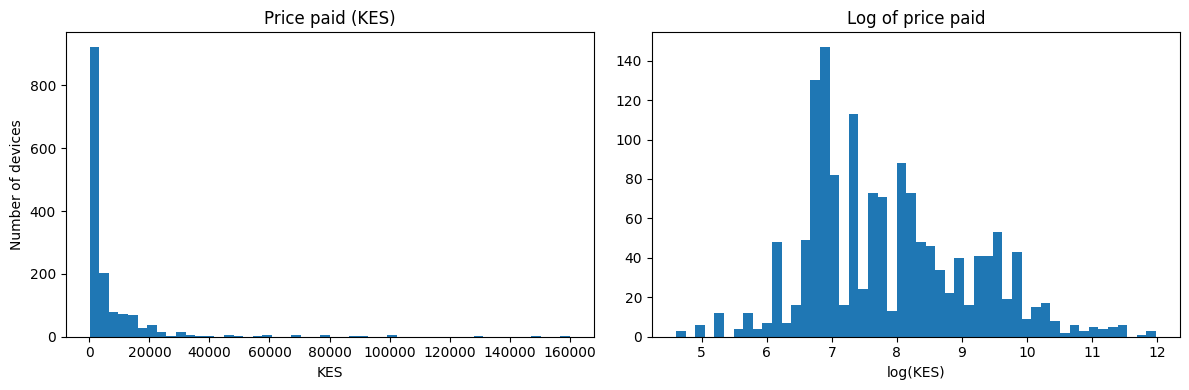

Skew of price: 5.83 | Skew of log price: 0.53


In [12]:
#histogram

df["log_price"] = np.log(df["price_kes"])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df["price_kes"], bins=50)
ax[0].set_title("Price paid (KES)"); ax[0].set_xlabel("KES"); ax[0].set_ylabel("Number of devices")
ax[1].hist(df["log_price"], bins=50)
ax[1].set_title("Log of price paid"); ax[1].set_xlabel("log(KES)")
plt.tight_layout(); plt.show()

print("Skew of price:", round(df["price_kes"].skew(), 2), "| Skew of log price:", round(df["log_price"].skew(), 2))

-The first histogram shows prices clustered near zero and a drastic fall to 160,000kes but in the second one after taking the algoritm , the plot with the log of price shows a bell curve shape.

-This proves that its better to predict log_price not raw prices to avoid having the mSE odmoinated by the the few very expensive systems and the model might fit these are the expense of typical prices. The predictions are then converted back to shillings with np.exp at the end.

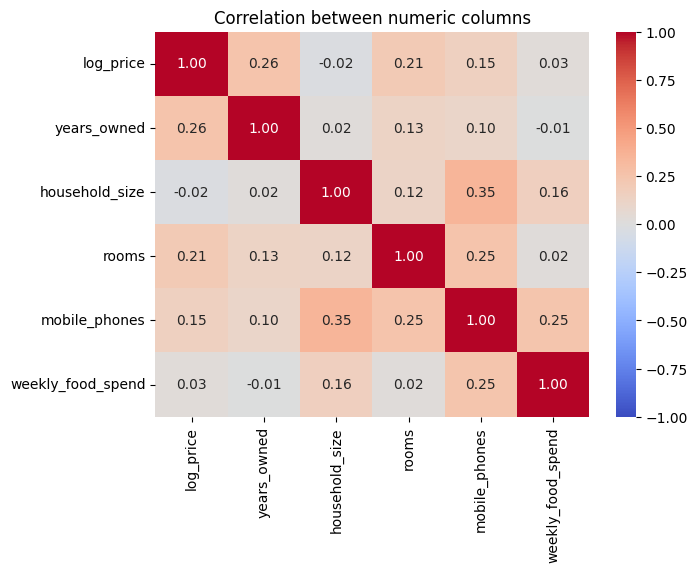

,log_price
years_owned,0.257476
rooms,0.208727
mobile_phones,0.151085
weekly_food_spend,0.025181
household_size,-0.018694


In [13]:
#heatmap
numeric = ["log_price", "years_owned", "household_size", "rooms", "mobile_phones", "weekly_food_spend"]
corr = df[numeric].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between numeric columns")
plt.show()

corr["log_price"].drop("log_price").sort_values(ascending=False)

-The numeric features have weak correlations with log price: the strongest is years_owned at 0.26. Collinearity between the features is also low (highest 0.35, household size and mobile phones), so none is redundant.. Older devices cost more probably because because solar prices have fallen over time and older purchases tend to be full home systems. Bigger homes and more phones signal a wealthier household that buys a bigger system. Food spending and household size carry almost no signal.

-Keep `years_owned`, `rooms` and `mobile_phones`. Drop `weekly_food_spend` and `household_size`. `years_owned` is the feature for the required scatter plots in section 8.

-**Limit of this plot.** It covers numeric columns only. The next plot is the evidence for the categorical ones.

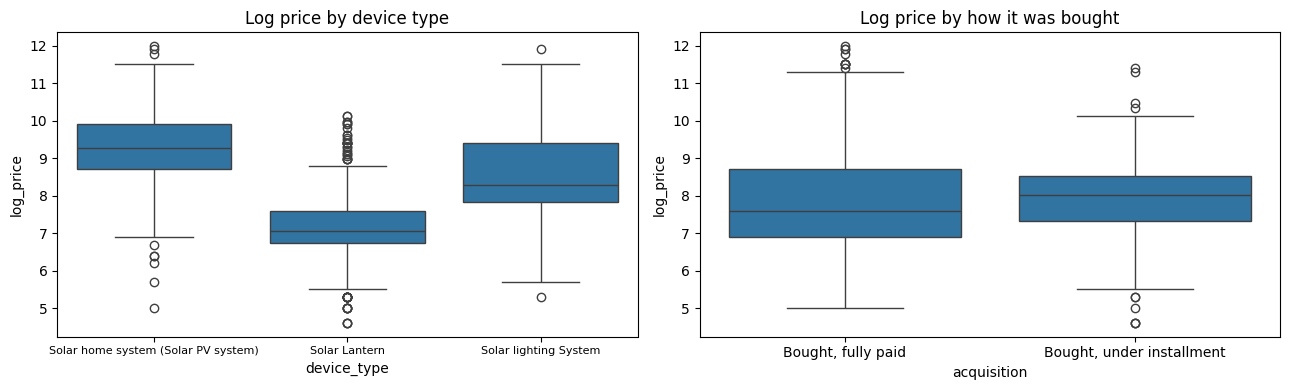

,count,median
device_type,,
Solar Lantern,846,1150.0
Solar home system (Solar PV system),252,10650.0
Solar lighting System,387,4000.0


In [14]:
#Boxplot
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x="device_type", y="log_price", ax=ax[0])
ax[0].set_title("Log price by device type"); ax[0].tick_params(axis="x", labelsize=8)
sns.boxplot(data=df, x="acquisition", y="log_price", ax=ax[1])
ax[1].set_title("Log price by how it was bought")
plt.tight_layout(); plt.show()

df.groupby("device_type")["price_kes"].agg(["count", "median"])

-The spread of log price for each device type and each way of buying.

-evice type separates prices far more clearly than any numeric feature. It will be the most important input.

-Keeping `device_type` and `acquisition`, and one-hot encode them. Because one feature carries so much, section 7 checks how much the others add.

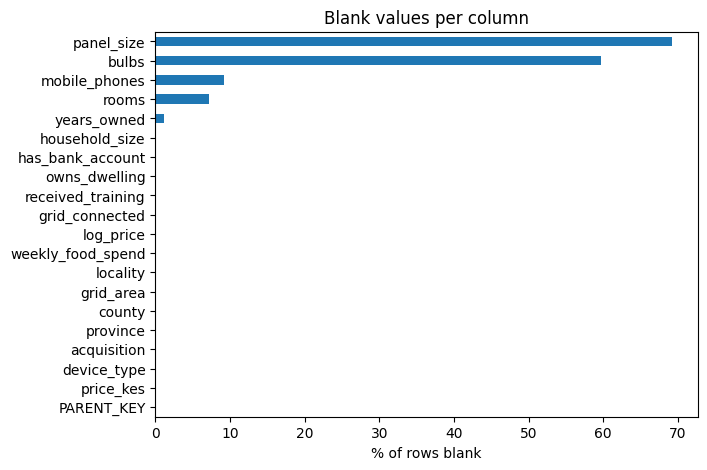

In [15]:
#bargraph
(df.isna().mean() * 100).sort_values().plot.barh(figsize=(7, 5))
plt.xlabel("% of rows blank"); plt.title("Blank values per column")
plt.show()

-This shows the share of blank values in each column
-Dropping `panel_size` and `bulbs`. Filling more than half(69%) a column with a guess would add noise. The other columns are complete enough to fill with the median or most common value.

3.**Feature engineering**

## 3. Feature engineering

**Columns dropped, and why**

| Column | Reason |
|---|---|
| `bulbs`, `panel_size` | Blank for 60% and 69% of devices |
| `weekly_food_spend`, `household_size` | Correlation with log price of 0.03 and -0.02 |
| `province` | The same information as `county`, at a coarser level |
| `grid_area` | Overlaps `locality` and `grid_connected` |
| `received_training` | Happens after the purchase, so a buyer checking a quote would not know it |
| `price_kes` | Replaced by `log_price`; keeping it as a feature would give away the answer |
| `PARENT_KEY` | An ID with no meaning; used only to split by household |

**Features kept: 10.** Seven categorical and three numeric, which meets the requirement for at least 8 features of mixed types. Each one becomes a text field in the app, and each is something a buyer knows before purchasing.

**Converting categorical to numeric.** This happens inside the pipeline in section 4, with `OneHotEncoder`. Doing it there, not with `pd.get_dummies`, means the encoder is saved with the model, so the API can turn the word "Nakuru" into the right columns.

In [16]:
cat_features = ["device_type", "acquisition", "county", "locality",
                "owns_dwelling", "grid_connected", "has_bank_account"]
num_features = ["years_owned", "rooms", "mobile_phones"]
features = cat_features + num_features
target = "log_price"

print(len(features), "features:", features)
df[features + [target]].head()

10 features: ['device_type', 'acquisition', 'county', 'locality', 'owns_dwelling', 'grid_connected', 'has_bank_account', 'years_owned', 'rooms', 'mobile_phones']


,device_type,acquisition,county,locality,owns_dwelling,grid_connected,has_bank_account,years_owned,rooms,mobile_phones,log_price
1,Solar home system (Solar PV system),"Bought, fully paid",Kajiado,Urban,Yes,No,No,5.0,NaN,3.0,11.512925
2,Solar Lantern,"Bought, fully paid",West Pokot,Rural,Yes,Yes,Yes,1.0,2.0,2.0,6.907755
3,Solar Lantern,"Bought, fully paid",West Pokot,Rural,Yes,Yes,Yes,1.0,2.0,2.0,6.907755
5,Solar Lantern,"Bought, fully paid",Narok,Rural,Yes,No,No,10.0,5.0,2.0,6.745236
6,Solar Lantern,"Bought, under installment",Turkana,Urban,Yes,No,No,2.0,2.0,2.0,6.214608


**4.Standarisation and splitting of data**


In [17]:
#setting aside  over 150 rows for testing.
# Set aside about 150 rows (whole households) as "new data" for the /retrain demo.
holder = GroupShuffleSplit(n_splits=1, test_size=150 / len(df), random_state=1)
keep_idx, new_idx = next(holder.split(df, groups=df["PARENT_KEY"]))

new_data = df.iloc[new_idx]
model_df = df.iloc[keep_idx].reset_index(drop=True)

new_data[features + ["price_kes"]].to_csv("API/new_data.csv", index=False)
print("Held back for retraining demo:", len(new_data), "| Left for modelling:", len(model_df))

Held back for retraining demo: 156 | Left for modelling: 1329


In [18]:
X = model_df[features]
y = model_df[target]
groups = model_df["PARENT_KEY"]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

shared = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
print("Train rows:", len(X_train), "| Test rows:", len(X_test), "| Households in both:", len(shared))

# Training rows in raw form, for the API's /retrain endpoint
model_df.iloc[train_idx][features + ["price_kes"]].to_csv("API/train_data.csv", index=False)

Train rows: 1061 | Test rows: 268 | Households in both: 0


-Splits 80% train and 20% test, keeping all of a household's devices on the same side. The training rows are also saved in raw form for the API.

-A household with two lanterns bought together has near-identical rows. A plain random split would put one in training and one in test, and the model would look better than it is on unseen households. Zero shared households confirms the test set is a fair check.

In [19]:
preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), num_features),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                               min_frequency=10, sparse_output=False))]), cat_features),
])

preprocessor.fit(X_train)                 # fitted on the training set ONLY
X_train_t = preprocessor.transform(X_train)
X_test_t = preprocessor.transform(X_test)

print("Before:", X_train.shape, "-> after encoding and scaling:", X_train_t.shape)
print("Mean of scaled numeric columns (train):", X_train_t[:, :len(num_features)].mean(axis=0).round(3))
print("Std of scaled numeric columns (train): ", X_train_t[:, :len(num_features)].std(axis=0).round(3))

Before: (1061, 10) -> after encoding and scaling: (1061, 56)
Mean of scaled numeric columns (train): [ 0.  0. -0.]
Std of scaled numeric columns (train):  [1. 1. 1.]


Standardising puts years, rooms and phones on one scale, which gradient descent needs: without it, the feature with the largest numbers dominates the updates. Fitting on training data only means the medians, means and categories are learned without looking at the test set. The test set is only ever transformed.

In [20]:
# A validation slice of the TRAINING set, used only for choosing hyperparameters.
val_split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=7)
fit_idx, val_idx = next(val_split.split(X_train_t, y_train, groups=groups.iloc[train_idx]))

X_fit_t, X_val_t = X_train_t[fit_idx], X_train_t[val_idx]
y_fit, y_val = y_train.iloc[fit_idx], y_train.iloc[val_idx]
print("Fit rows:", len(y_fit), "| Validation rows:", len(y_val))

Fit rows: 857 | Validation rows: 204


Hyperparameters are chosen on this slice, not on the test set. If settings were picked by test score, the test set would stop being an honest final check.

**5.Training models**

All losses in this section are in log-price units, because that is what the models predict.

In [22]:
def huber_loss(y_true, y_pred, delta=1.0):
    """Squared error for small misses, absolute error for misses larger than delta."""
    err = np.abs(np.asarray(y_true) - np.asarray(y_pred))
    return float(np.mean(np.where(err <= delta, 0.5 * err**2, delta * (err - 0.5 * delta))))


def train_sgd(X_a, y_a, X_b, y_b, eta0=0.01, alpha=0.0001, n_epochs=100,
              loss="squared_error", epsilon=0.1, seed=42):
    """Train SGDRegressor one epoch at a time; return the model and the MSE on both sets per epoch."""
    model = SGDRegressor(loss=loss, epsilon=epsilon, penalty="l2", alpha=alpha,
                         learning_rate="constant", eta0=eta0, random_state=seed)
    rng = np.random.default_rng(seed)
    y_a = np.asarray(y_a)
    losses_a, losses_b = [], []
    for epoch in range(n_epochs):
        order = rng.permutation(len(X_a))            # reshuffle the rows every epoch
        model.partial_fit(X_a[order], y_a[order])    # one pass over the data
        losses_a.append(mean_squared_error(y_a, model.predict(X_a)))
        losses_b.append(mean_squared_error(y_b, model.predict(X_b)))
    return model, losses_a, losses_b

this defines the helpers including huber_loss which squares small errors and treats large ones linearly  so that few big misses do not dominate, used in section 6 and 9.

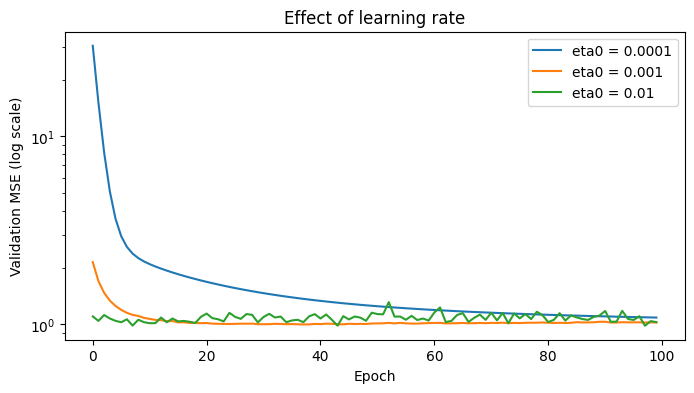

,learning rate (eta0),train MSE,validation MSE
0,0.0001,8.273333e-01,1.086082e+00
1,0.0010,7.426527e-01,1.021657e+00
2,0.0100,7.514300e-01,1.027511e+00
3,0.1000,9.297796e+00,6.927645e+00
4,1.0000,1.442527e+26,1.205045e+26


In [28]:
#Tunning learning Rate
from sklearn.linear_model import SGDRegressor

rows = []
curves = {}
for eta0 in [0.0001, 0.001, 0.01, 0.1, 1.0]:
    _, tr, va = train_sgd(X_fit_t, y_fit, X_val_t, y_val, eta0=eta0, alpha=0.0001, n_epochs=100)
    curves[eta0] = va
    rows.append({"learning rate (eta0)": eta0, "train MSE": tr[-1], "validation MSE": va[-1]})
lr_table = pd.DataFrame(rows)

plt.figure(figsize=(8, 4))
for eta0, va in curves.items():
    if max(va) < 50:                                   # leave exploded runs off the chart
        plt.plot(va, label=f"eta0 = {eta0}")
plt.yscale("log")
plt.xlabel("Epoch"); plt.ylabel("Validation MSE (log scale)"); plt.title("Effect of learning rate"); plt.legend()
plt.show()
lr_table

At 0.0001 the steps are so small that 100 epochs are not enough to reach the bottom. At 0.1 and above, each step overshoots and the loss grows instead of shrinking. 0.001 is the largest rate that still converges smoothly.
Hence the decision to use 0.001

In [29]:
best_eta0 = lr_table.loc[lr_table["validation MSE"].idxmin(), "learning rate (eta0)"]

rows = []
for alpha in [0.00001, 0.0001, 0.001, 0.01, 0.1, 1.0]:
    _, tr, va = train_sgd(X_fit_t, y_fit, X_val_t, y_val, eta0=best_eta0, alpha=alpha, n_epochs=100)
    rows.append({"regularisation (alpha)": alpha, "train MSE": tr[-1], "validation MSE": va[-1]})
alpha_table = pd.DataFrame(rows)
print("Learning rate used:", best_eta0)
alpha_table

Learning rate used: 0.001


,regularisation (alpha),train MSE,validation MSE
0,0.00001,0.742581,1.021936
1,0.00010,0.742653,1.021657
2,0.00100,0.743417,1.019037
3,0.01000,0.753879,1.004888
4,0.10000,0.839469,1.056096
5,1.00000,1.186165,1.342354


From that table training MSE raises steadily as alpa grows. This means that Alpha penalises large weighs, small values change very little , moderate values(eg 0.1) trims the weights on sparse county oclumsn and generalizes slight better. large values shrink every weight towards zewro so models underfit , both train and validation loss get worse.Decided to use alpha = 0.01 though the improvement is not much.

In [30]:
#tunning number of epochs
best_alpha = alpha_table.loc[alpha_table["validation MSE"].idxmin(), "regularisation (alpha)"]

_, tr, va = train_sgd(X_fit_t, y_fit, X_val_t, y_val, eta0=best_eta0, alpha=best_alpha, n_epochs=300)
epoch_table = pd.DataFrame({"epochs": [10, 20, 50, 100, 200, 300]})
epoch_table["train MSE"] = [tr[e - 1] for e in epoch_table["epochs"]]
epoch_table["validation MSE"] = [va[e - 1] for e in epoch_table["epochs"]]
print("Learning rate:", best_eta0, "| alpha:", best_alpha)
epoch_table

Learning rate: 0.001 | alpha: 0.01


,epochs,train MSE,validation MSE
0,10,0.833691,1.087209
1,20,0.792889,1.019706
2,50,0.767740,1.009989
3,100,0.753879,1.004888
4,200,0.750602,1.012751
5,300,0.750921,1.015629


-Validation MSE falls quickly from 1.09 at 10 epochs to 1.02 at 20, reaches its lowest at 100 (1.005), and creeps up slightly at 200 and 300. Train MSE keeps edging down.

-Most learning happens in the first 20 passes. After about 100, extra passes only fit the training rows more closely without helping on unseen ones.

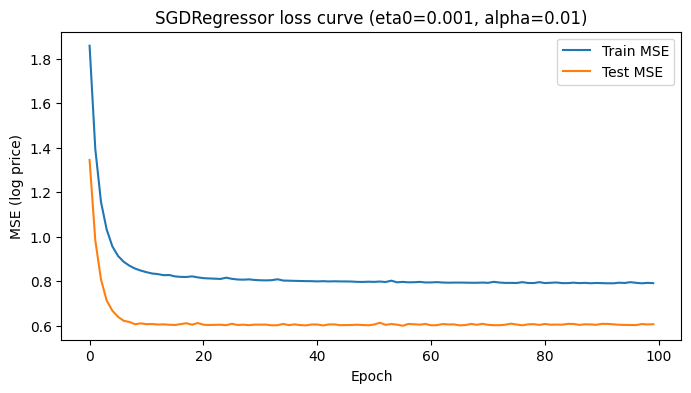

Epoch 1   -> train MSE 1.859 | test MSE 1.345
Epoch 100 -> train MSE 0.791 | test MSE 0.606


In [32]:

#Final SGD model and loss curve

best_epochs = 100

sgd_model, sgd_train_losses, sgd_test_losses = train_sgd(
    X_train_t, y_train, X_test_t, y_test, eta0=best_eta0, alpha=best_alpha, n_epochs=best_epochs)

plt.figure(figsize=(8, 4))
plt.plot(sgd_train_losses, label="Train MSE")
plt.plot(sgd_test_losses, label="Test MSE")
plt.xlabel("Epoch"); plt.ylabel("MSE (log price)")
plt.title(f"SGDRegressor loss curve (eta0={best_eta0}, alpha={best_alpha})")
plt.legend(); plt.show()

print("Epoch 1   -> train MSE %.3f | test MSE %.3f" % (sgd_train_losses[0], sgd_test_losses[0]))
print("Epoch %d -> train MSE %.3f | test MSE %.3f" % (best_epochs, sgd_train_losses[-1], sgd_test_losses[-1]))

- Both curves fall together and flatten, with no point where the test line turns upward. The model has converged and is not overfitting.
- The test line sits *below* the train line, which is unusual. The test set happens to contain prices that are less spread out (its baseline MSE is 1.32, lower than the training set's), so it is easier to predict. With only 268 test rows, which households land in the test set moves the number noticeably. Section 6.2 measures that.

In [33]:
# LinearRegression
linear_model = LinearRegression().fit(X_train_t, y_train)
print("LinearRegression  train MSE %.3f | test MSE %.3f" % (
    mean_squared_error(y_train, linear_model.predict(X_train_t)),
    mean_squared_error(y_test, linear_model.predict(X_test_t))))

LinearRegression  train MSE 0.779 | test MSE 0.623


This solves the same straight-line model exactly, in one step, with no learning rate or epochs. It lands within 0.02 of the SGD model, which confirms gradient descent reached essentially the same solution. SGD is marginally better on test because its regularisation (alpha = 0.01) slightly shrinks the weights on rare counties; plain `LinearRegression` has no regularisation, so it fits training data a little more closely (lower train MSE) and generalises a little worse.

**5.6 Decision tree and random forest**

In [34]:
rows = []
for depth in [2, 3, 4, 5, 6, 8, None]:
    t = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=10, random_state=42).fit(X_fit_t, y_fit)
    rows.append({"max_depth": "unlimited" if depth is None else depth,
                 "train MSE": mean_squared_error(y_fit, t.predict(X_fit_t)),
                 "validation MSE": mean_squared_error(y_val, t.predict(X_val_t))})
tree_table = pd.DataFrame(rows)

# For contrast: a fully grown tree with no limits at all
overfit = DecisionTreeRegressor(random_state=42).fit(X_fit_t, y_fit)
print("No limits at all -> train MSE %.3f | validation MSE %.3f" % (
    mean_squared_error(y_fit, overfit.predict(X_fit_t)), mean_squared_error(y_val, overfit.predict(X_val_t))))
tree_table.round(3)

No limits at all -> train MSE 0.056 | validation MSE 1.164


,max_depth,train MSE,validation MSE
0,2,0.860,0.903
1,3,0.817,0.940
2,4,0.770,0.940
3,5,0.744,0.894
4,6,0.723,0.896
5,8,0.688,0.929
6,unlimited,0.663,0.951


The unlimited tree memorises the training rows (near-zero training error) and then does worse on new households than every other setting. That gap is overfitting. Limiting depth forces the tree to learn broad rules, such as "home systems in this group of counties", instead of individual devices.

-Tree depth chosen: 5

**6. Comparing the four models**

6.1 Results on the test set

In [37]:
# Fit the decision tree and random forest models using the selected parameters
from sklearn.metrics import median_absolute_error

tree_model = DecisionTreeRegressor(max_depth=5, min_samples_leaf=10, random_state=42).fit(X_train_t, y_train)
forest_model = RandomForestRegressor(n_estimators=100, max_depth=5, min_samples_leaf=10, random_state=42).fit(X_train_t, y_train)

models = {
    "SGDRegressor (gradient descent)": sgd_model,
    "LinearRegression (closed form)": linear_model,
    "DecisionTreeRegressor": tree_model,
    "RandomForestRegressor": forest_model,
}

rows = []
for name, m in models.items():
    p_train, p_test = m.predict(X_train_t), m.predict(X_test_t)
    rows.append({"model": name,
                 "train MSE": mean_squared_error(y_train, p_train),
                 "test MSE": mean_squared_error(y_test, p_test),
                 "test MAE": mean_absolute_error(y_test, p_test),
                 "test MedAE": median_absolute_error(y_test, p_test),
                 "test Huber": huber_loss(y_test, p_test),
                 "median miss (KES)": median_absolute_error(np.exp(y_test), np.exp(p_test))})
results = pd.DataFrame(rows).set_index("model").sort_values("test MSE")

baseline_mse = mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))
best_name = results["test MSE"].idxmin()
print("Baseline (always predict the training average): test MSE %.3f" % baseline_mse)
print("Best model by test MSE:", best_name)
print("It explains %.0f%% of the variation in log price on the test set" % (100 * (1 - results.loc[best_name, "test MSE"].values[0] / baseline_mse)) if hasattr(results.loc[best_name, "test MSE"], 'values') else (100 * (1 - results.loc[best_name, "test MSE"] / baseline_mse)))
results.round(3)

Baseline (always predict the training average): test MSE 1.324
Best model by test MSE: SGDRegressor (gradient descent)
54.213533473582366


,train MSE,test MSE,test MAE,test MedAE,test Huber,median miss (KES)
model,,,,,,
SGDRegressor (gradient descent),0.791,0.606,0.583,0.413,0.270,963.958
LinearRegression (closed form),0.779,0.623,0.587,0.448,0.275,916.500
RandomForestRegressor,0.738,0.632,0.601,0.436,0.276,1046.214
DecisionTreeRegressor,0.771,0.666,0.624,0.473,0.291,1162.404


- **All four beat the baseline by a wide margin.** The best model explains about 54% of the variation in log price on the test set.
- **The two linear models are nearly identical,** as expected: same model, two fitting methods.
- **The linear models beat the trees on MSE.** Price is driven mainly by device type plus roughly additive shifts for county and household wealth, which a straight-line model captures efficiently. With only 1,061 training rows over 45 counties, the trees have too little data per county.
- **The metrics disagree, and that is informative.** The random forest has the *worst* test MSE but the *best* MedAE (0.385). It is closest on the typical device but makes the largest misses, and MSE punishes large misses most. SGD makes fewer big mistakes, which is what MSE rewards.
- **The random forest overfits most:** train MSE 0.39 against test MSE 0.69, the largest gap.
- **In shillings,** half of SGD's predictions are within about 960 KES of the actual price, against a median price of 2,000 KES.

**6.2 How much does the result depend on the split?**

In [39]:
best_depth = 5

def as_pipeline(estimator):
    return Pipeline([("prep", preprocessor), ("model", estimator)])

candidates = {
    "SGDRegressor": SGDRegressor(alpha=best_alpha, learning_rate="constant", eta0=best_eta0,
                                 max_iter=best_epochs, tol=None, random_state=42),
    "LinearRegression": LinearRegression(),
    "DecisionTreeRegressor": DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=10, random_state=42),
    "RandomForestRegressor": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42),
}

rows = []
for name, est in candidates.items():
    scores = -cross_val_score(as_pipeline(est), X, y, groups=groups, cv=GroupKFold(n_splits=5),
                              scoring="neg_mean_squared_error")
    rows.append({"model": name, "mean MSE over 5 folds": scores.mean(), "lowest": scores.min(), "highest": scores.max()})
pd.DataFrame(rows).set_index("model").sort_values("mean MSE over 5 folds").round(3)

,mean MSE over 5 folds,lowest,highest
model,,,
RandomForestRegressor,0.811,0.652,0.924
SGDRegressor,0.820,0.621,0.968
LinearRegression,0.833,0.627,0.963
DecisionTreeRegressor,0.850,0.644,0.984


-Repeats the comparison five times, each time holding out a different fifth of the households, and averages the test MSE.

-The four models perform about equally on this dataset. The differences in the main table are smaller than the variation from one split to another, so the ranking there is partly luck of the split. This also shows that the main test MSE of 0.61 was a favourable split; about 0.8 is the more representative figure.

**6.3 Which features matter most**

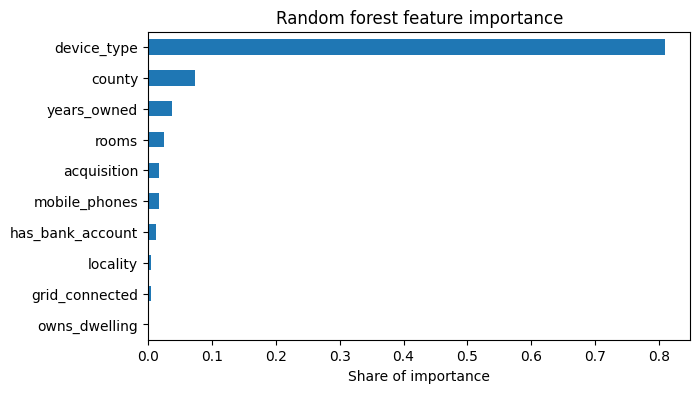

,0
device_type,0.809
county,0.073
years_owned,0.037
rooms,0.025
acquisition,0.017
mobile_phones,0.017
has_bank_account,0.012
locality,0.005
grid_connected,0.005
owns_dwelling,0.001


In [40]:
encoded_names = preprocessor.get_feature_names_out()
importance = pd.Series(forest_model.feature_importances_, index=encoded_names)

# Add the one-hot columns back together so there is one bar per original feature
def original(name):
    name = name.split("__", 1)[1]
    for f in features:
        if name == f or name.startswith(f + "_"):
            return f
    return name

by_feature = importance.groupby(original).sum().sort_values()
by_feature.plot.barh(figsize=(7, 4))
plt.xlabel("Share of importance"); plt.title("Random forest feature importance")
plt.show()
by_feature.sort_values(ascending=False).round(3)

Device type carries more than half the predictive power, as the box plot suggested. Location is clearly second. The household features add smaller but real contributions. `owns_dwelling` and `grid_connected` contribute least and are candidates to remove if you want fewer app inputs.

**7. Scatter plots, before and after**

Numeric feature most correlated with log price: years_owned (r = 0.25)


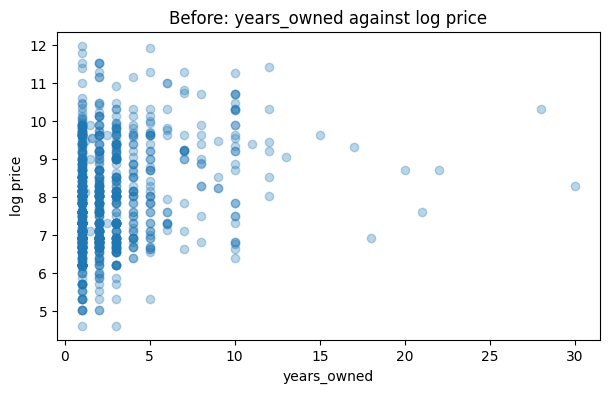

In [41]:
num_corr = model_df.iloc[train_idx][num_features + [target]].corr()[target].drop(target)
top_feature = num_corr.abs().idxmax()
print("Numeric feature most correlated with log price:", top_feature, "(r = %.2f)" % num_corr[top_feature])

plot_df = pd.DataFrame({top_feature: X_train[top_feature], target: y_train}).dropna()

plt.figure(figsize=(7, 4))
plt.scatter(plot_df[top_feature], plot_df[target], alpha=0.3)
plt.xlabel(top_feature); plt.ylabel("log price")
plt.title("Before: " + top_feature + " against log price")
plt.show()

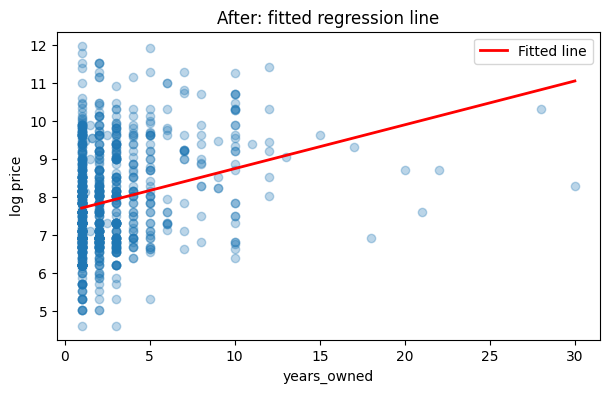

Slope 0.115 | intercept 7.587 | R squared 0.061


In [42]:
# One-feature linear regression, for this plot only
one_feature = LinearRegression().fit(plot_df[[top_feature]], plot_df[target])
xs = pd.DataFrame({top_feature: np.linspace(plot_df[top_feature].min(), plot_df[top_feature].max(), 100)})

plt.figure(figsize=(7, 4))
plt.scatter(plot_df[top_feature], plot_df[target], alpha=0.3)
plt.plot(xs[top_feature], one_feature.predict(xs), color="red", linewidth=2, label="Fitted line")
plt.xlabel(top_feature); plt.ylabel("log price")
plt.title("After: fitted regression line")
plt.legend(); plt.show()

print("Slope %.3f | intercept %.3f | R squared %.3f" % (
    one_feature.coef_[0], one_feature.intercept_, one_feature.score(plot_df[[top_feature]], plot_df[target])))

Each extra year of ownership goes with about 12% higher price paid (a slope of 0.115 in log units). The line explains only about 6% of the variation, which is why one feature is not enough: the full model with ten features explains about 54% on the same test set.

**8. Saving the best model and predicting**

In [43]:
best_model = models[best_name]
best_pipeline = Pipeline([("prep", preprocessor), ("model", best_model)])   # both parts are already fitted
joblib.dump(best_pipeline, "API/best_model.pkl")
print("Saved:", best_name, "-> API/best_model.pkl (%.0f KB)" % (os.path.getsize("API/best_model.pkl") / 1024))

Saved: SGDRegressor (gradient descent) -> API/best_model.pkl (7 KB)


In [44]:
def predict_price(row: dict, model_path: str = "API/best_model.pkl") -> float:
    """Load the saved pipeline and return the predicted upfront price in KES for one device."""
    pipeline = joblib.load(model_path)
    X_one = pd.DataFrame([row])
    log_price = pipeline.predict(X_one)[0]
    return float(np.exp(log_price))          # the model predicts log price, so convert back


row = X_test.iloc[0].to_dict()               # one row of the test set, in raw form
print("Input:", row)
print("Predicted price: KES %.0f" % predict_price(row))
print("Actual price:    KES %.0f" % np.exp(y_test.iloc[0]))

Input: {'device_type': 'Solar Lantern', 'acquisition': 'Bought, fully paid', 'county': 'West Pokot', 'locality': 'Rural', 'owns_dwelling': 'Yes', 'grid_connected': 'No', 'has_bank_account': 'No', 'years_owned': 2.0, 'rooms': 4.0, 'mobile_phones': 1.0}
Predicted price: KES 1470
Actual price:    KES 1000


**9. Extra experiment: MSE, MAE, MedAE and Huber**

9.1 How each loss penalises an error

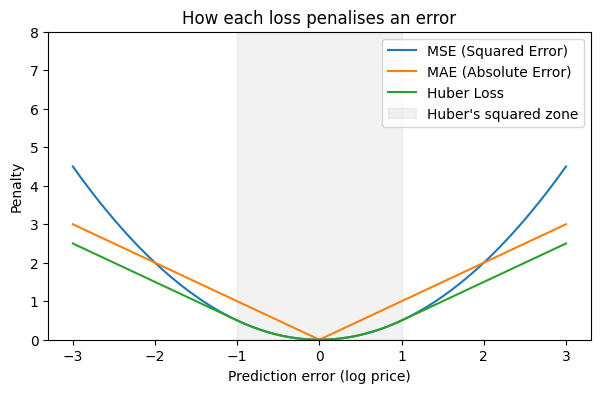

In [46]:
# Define variables for the loss visualization
delta = 1.0
err = np.linspace(-3, 3, 300)

# Calculate penalties for each loss function
shapes = {
    "MSE (Squared Error)": 0.5 * err**2,
    "MAE (Absolute Error)": np.abs(err),
    "Huber Loss": np.where(np.abs(err) <= delta, 0.5 * err**2, delta * (np.abs(err) - 0.5 * delta))
}

plt.figure(figsize=(7, 4))
for name, penalty in shapes.items():
    plt.plot(err, penalty, label=name)
plt.axvspan(-delta, delta, color="grey", alpha=0.1, label="Huber's squared zone")
plt.ylim(0, 8)
plt.xlabel("Prediction error (log price)"); plt.ylabel("Penalty")
plt.title("How each loss penalises an error"); plt.legend()
plt.show()

-The penalty each loss gives to a miss of a given size. Inside the grey band (errors smaller than 1), Huber behaves like MSE; outside it, Huber rises in a straight line like MAE.

-A miss of 3 costs 9 under MSE but only 3 under MAE and 2.5 under Huber. So a model trained on MSE is pulled hard towards the few devices it misses badly, such as unusually expensive home systems. MAE and Huber let those misses cost less and focus on the bulk of the devices.

-In log units, an error of 1 means a prediction off by a factor of about 2.7, so Huber's cut-off of 1 treats anything worse than that as an outlier.

9.2 Training each SGD

In [47]:
loss_settings = {
    "MSE (squared_error)":        dict(loss="squared_error"),
    "Huber (delta = 1)":          dict(loss="huber", epsilon=1.0),
    "MAE (epsilon_insensitive)":  dict(loss="epsilon_insensitive", epsilon=0.0),
}

rows = []
for name, kw in loss_settings.items():
    m, _, _ = train_sgd(X_train_t, y_train, X_test_t, y_test,
                        eta0=best_eta0, alpha=best_alpha, n_epochs=best_epochs, **kw)
    pred = m.predict(X_test_t)
    rows.append({"trained to minimise": name,
                 "test MSE": mean_squared_error(y_test, pred),
                 "test MAE": mean_absolute_error(y_test, pred),
                 "test MedAE": median_absolute_error(y_test, pred),
                 "test Huber": huber_loss(y_test, pred)})
pd.DataFrame(rows).set_index("trained to minimise").round(3)

,test MSE,test MAE,test MedAE,test Huber
trained to minimise,,,,
MSE (squared_error),0.606,0.583,0.413,0.270
Huber (delta = 1),0.616,0.582,0.394,0.272
MAE (epsilon_insensitive),0.632,0.574,0.396,0.275


Trains the same SGD model three times, changing only the loss it minimises, and scores each version four ways. MedAE cannot be a training loss for SGD, so it appears only as a score.

-The MSE-trained model has the lowest MSE and the MAE-trained model has the lowest MAE: each wins on the measure it was trained for.

- Huber and MAE training improve MedAE (0.394 and 0.396 against 0.413). Caring less about big misses gets them closer on the typical device.

- The differences are small, about 4% on MSE. The log target had already removed most of the outlier effect these losses are designed to handle.

**Decision.** Keep the MSE-trained model as the saved model, because the assignment selects by test MSE.

**9.3 Training curves for three loses**

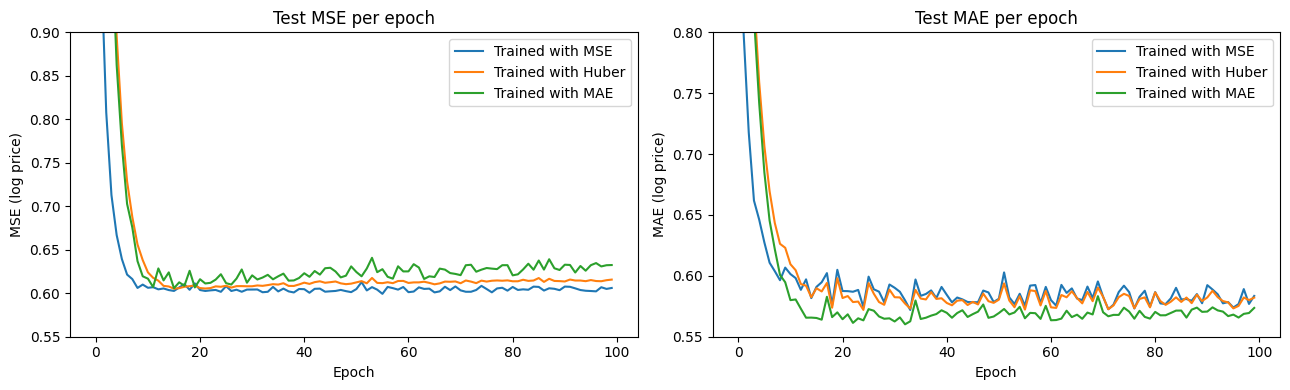

In [48]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, kw in loss_settings.items():
    model = SGDRegressor(penalty="l2", alpha=best_alpha, learning_rate="constant",
                         eta0=best_eta0, random_state=42, **kw)
    rng = np.random.default_rng(42)
    y_arr = np.asarray(y_train)
    mse_curve, mae_curve = [], []
    for epoch in range(best_epochs):
        order = rng.permutation(len(X_train_t))
        model.partial_fit(X_train_t[order], y_arr[order])
        pred = model.predict(X_test_t)
        mse_curve.append(mean_squared_error(y_test, pred))
        mae_curve.append(mean_absolute_error(y_test, pred))
    ax[0].plot(mse_curve, label="Trained with " + name.split(" (")[0])
    ax[1].plot(mae_curve, label="Trained with " + name.split(" (")[0])

ax[0].set_title("Test MSE per epoch"); ax[0].set_ylabel("MSE (log price)")
ax[1].set_title("Test MAE per epoch"); ax[1].set_ylabel("MAE (log price)")
for a in ax:
    a.set_xlabel("Epoch"); a.legend()
ax[0].set_ylim(0.55, 0.9); ax[1].set_ylim(0.55, 0.8)
plt.tight_layout(); plt.show()

-All three drop steeply at the start. The MSE-trained line settles within about 5 epochs; the Huber and MAE versions take about 10. After that, the MSE-trained line stays lowest on the left panel and the MAE-trained line lowest on the right. The lines wobble because the learning rate is constant.

-MSE training converges fastest because its updates are larger when errors are large. MAE and Huber take steps of the same size whatever the error, so they approach more slowly. The final gaps are small, which repeats the finding of section 9.2.

**10.API**

**10.1 Input ranges for the API**

In [49]:
print(model_df[num_features].describe().loc[["min", "50%", "max"]].T)
print()
for c in cat_features:
    values = sorted(model_df[c].dropna().unique())
    print(f"{c} ({len(values)} values):", values if len(values) <= 6 else values[:6] + ["..."])

               min  50%   max
years_owned    1.0  2.0  30.0
rooms          1.0  3.0  25.0
mobile_phones  0.0  2.0  10.0

device_type (3 values): ['Solar Lantern', 'Solar home system (Solar PV system)', 'Solar lighting System']
acquisition (2 values): ['Bought, fully paid', 'Bought, under installment']
county (45 values): ['Baringo', 'Bomet', 'Bungoma', 'Busia', 'Elgeyo Marakwet', 'Embu', '...']
locality (2 values): ['Rural', 'Urban']
owns_dwelling (2 values): ['No', 'Yes']
grid_connected (2 values): ['No', 'Yes']
has_bank_account (2 values): ['No', 'Yes']


-These become the Pydantic constraints in the API: `years_owned` from 1 to 30, `rooms` from 1 to 25, `mobile_phones` from 0 to 10, and a fixed set of choices for each categorical field

**10.2 UV files**

In [50]:
# Creates pyproject.toml, uv.lock and requirements.txt with uv, in a staging folder called summative.
SK = sklearn.__version__
print("Pinning scikit-learn", SK)

!pip install -q uv
!rm -rf summative && mkdir -p summative/API
!cd summative && uv init --bare -q && uv add -q "scikit-learn=={SK}" pandas numpy joblib fastapi uvicorn pydantic python-multipart && uv add -q --dev matplotlib seaborn && uv export -q --format requirements.txt --no-hashes --no-dev -o API/requirements.txt
!grep -E "^(scikit-learn|fastapi|pandas|uvicorn)==" summative/API/requirements.txt

Pinning scikit-learn 1.6.1
fastapi==0.165.0
pandas==3.1.1
scikit-learn==1.6.1
uvicorn==0.54.0


**10.3 downloads for repo**

In [52]:
import sys
IN_COLAB = "google.colab" in sys.modules

to_download = ["API/best_model.pkl", "API/train_data.csv", "API/new_data.csv",
               "summative/pyproject.toml", "summative/uv.lock", "summative/API/requirements.txt"]

for f in to_download:
    print(f, "-", round(os.path.getsize(f) / 1024), "KB")

if IN_COLAB:
    from google.colab import files
    for f in to_download:
        files.download(f)

API/best_model.pkl - 7 KB
API/train_data.csv - 88 KB
API/new_data.csv - 13 KB
summative/pyproject.toml - 0 KB
summative/uv.lock - 182 KB
summative/API/requirements.txt - 1 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (3 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>